# Tox21 Preprocessing: Exploratory Data Analysis and Scaffold Split

This notebook covers **five tasks**:

1. Use the Tox21 dataset.
2. Inspect the SMILES column and all 12 target (assay) columns.
3. Check missing values, duplicate structures, invalid SMILES and class imbalance.
4. Canonicalize valid SMILES with RDKit, with a clear policy for duplicates and conflicting labels.
5. Make a reproducible scaffold-based train / validation / test split (random seed = 42).

**Rules followed throughout**
* The original CSV file is only *read*. It is never modified or overwritten.
* Missing toxicity labels stay missing (`NaN`). They are **never** replaced with 0.
* Nothing is silently deleted. Every excluded row is written to a report file.

**Files used:** `tox21 3.csv` (data), `data_pipeline.py` and `scaffold_split.py` (helper functions).
Each helper function is short. Open the `.py` files to read them line by line.

## 1. Setup

**What:** installs RDKit if it is missing (Google Colab does not include it) and imports the libraries.
**Why:** RDKit is the chemistry library that reads SMILES strings.

In [ ]:
try:
    import rdkit
except ImportError:
    %pip install -q rdkit

import os
import hashlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import rdkit
from rdkit import Chem

print("pandas:", pd.__version__)
print("numpy :", np.__version__)
print("rdkit :", rdkit.__version__)

pandas: 3.0.6
numpy : 2.4.6
rdkit : 2026.09.1


### 1.1 Find the files (upload them in Colab if needed)

**What:** checks that the CSV and the two helper `.py` files are in the current folder.
If you are in Google Colab and a file is missing, an upload button appears.

In [ ]:
DATA_FILE = "tox21 3.csv"
needed_files = [DATA_FILE, "data_pipeline.py", "scaffold_split.py"]

missing_files = []
for file_name in needed_files:
    if not os.path.exists(file_name):
        missing_files.append(file_name)

if len(missing_files) > 0:
    print("Missing files:", missing_files)
    try:
        from google.colab import files
        print("Please upload the missing files now.")
        files.upload()
    except ImportError:
        raise FileNotFoundError("Put these files in the same folder as this notebook: " + str(missing_files))
else:
    print("All needed files found in:", os.getcwd())

All needed files found in: /Users/tanisha/Molecular-Toxicity-Prediction-/tox21_project


In [ ]:
import data_pipeline as dp
import scaffold_split as ss

# Record exactly which file is used
with open(DATA_FILE, "rb") as f:
    file_checksum = hashlib.sha256(f.read()).hexdigest()
print("File:", DATA_FILE)
print("SHA-256:", file_checksum)

File: tox21 3.csv
SHA-256: 7d7e7facd853a63e79ddce4e9c3fcb7a0d83a1c300b603031c0f2c64fbe77761


## 2. Load the data and inspect the columns

**What:** reads the CSV *as it is* and shows its shape, first five rows and data types.
**Why:** before cleaning anything we must know what is really in the file.
**Expected:** 7,831 rows and 14 columns (12 assays + `mol_id` + `smiles`).

In [ ]:
df_raw = dp.load_dataset(DATA_FILE)

print("Shape (rows, columns):", df_raw.shape)
df_raw.head()

Shape (rows, columns): (7831, 14)


,NR-AR,NR-AR-LBD,NR-AhR,NR-Aromatase,NR-ER,NR-ER-LBD,NR-PPAR-gamma,SR-ARE,SR-ATAD5,SR-HSE,SR-MMP,SR-p53,mol_id,smiles
0,0.0,0.0,1.0,NaN,NaN,0.0,0.0,1.0,0.0,0.0,0.0,0.0,TOX3021,CCOc1ccc2nc(S(N)(=O)=O)sc2c1
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,0.0,0.0,TOX3020,CCN1C(=O)NC(c2ccccc2)C1=O
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN,NaN,TOX3024,CC[C@]1(O)CC[C@H]2[C@@H]3CCC4=CCCC[C@@H]4[C@H]...
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,0.0,0.0,TOX3027,CCCN(CC)C(CC)C(=O)Nc1c(C)cccc1C
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,TOX20800,CC(O)(P(=O)(O)O)P(=O)(O)O


In [ ]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7831 entries, 0 to 7830
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   NR-AR          7265 non-null   float64
 1   NR-AR-LBD      6758 non-null   float64
 2   NR-AhR         6549 non-null   float64
 3   NR-Aromatase   5821 non-null   float64
 4   NR-ER          6193 non-null   float64
 5   NR-ER-LBD      6955 non-null   float64
 6   NR-PPAR-gamma  6450 non-null   float64
 7   SR-ARE         5832 non-null   float64
 8   SR-ATAD5       7072 non-null   float64
 9   SR-HSE         6467 non-null   float64
 10  SR-MMP         5810 non-null   float64
 11  SR-p53         6774 non-null   float64
 12  mol_id         7831 non-null   str    
 13  smiles         7831 non-null   str    
dtypes: float64(12), str(2)
memory usage: 856.6 KB


`info()`:** the 12 assay columns are `float64`, because pandas stores a missing value as `NaN`, and `NaN` is a float.
The *Non-Null Count* is smaller than 7,831 for the assays, so some labels are missing.
`mol_id` and `smiles` are text and have no missing values.

Now we check that the column names are exactly the ones we expect.

In [ ]:
TARGET_COLUMNS = dp.TARGET_COLUMNS
print("Expected target columns:", TARGET_COLUMNS)

column_check = dp.check_columns(df_raw)
print("Expected but missing columns:", column_check["missing_columns"])
print("Unexpected extra columns   :", column_check["extra_columns"])

if len(column_check["missing_columns"]) > 0:
    raise ValueError("Some expected columns are missing. Stop and check the file.")

Expected target columns: ['NR-AR', 'NR-AR-LBD', 'NR-AhR', 'NR-Aromatase', 'NR-ER', 'NR-ER-LBD', 'NR-PPAR-gamma', 'SR-ARE', 'SR-ATAD5', 'SR-HSE', 'SR-MMP', 'SR-p53']
Expected but missing columns: []
Unexpected extra columns   : []


### 2.1 Are the target values only 0, 1 or missing?

**What:** lists every value that appears in each assay column and counts anything unexpected (e.g. `2`, `"active"`, `-1`).
**Why:** a silent conversion of strange values to `NaN` would hide a data problem. We **report** instead of converting.

In [ ]:
target_value_check = dp.check_target_values(df_raw)
target_value_check

,assay,dtype,values_found,n_missing,n_unexpected_values,unexpected_values
0,NR-AR,float64,"[0.0, 1.0]",566,0,[]
1,NR-AR-LBD,float64,"[0.0, 1.0]",1073,0,[]
2,NR-AhR,float64,"[0.0, 1.0]",1282,0,[]
3,NR-Aromatase,float64,"[0.0, 1.0]",2010,0,[]
4,NR-ER,float64,"[0.0, 1.0]",1638,0,[]
5,NR-ER-LBD,float64,"[0.0, 1.0]",876,0,[]
6,NR-PPAR-gamma,float64,"[0.0, 1.0]",1381,0,[]
7,SR-ARE,float64,"[0.0, 1.0]",1999,0,[]
8,SR-ATAD5,float64,"[0.0, 1.0]",759,0,[]
9,SR-HSE,float64,"[0.0, 1.0]",1364,0,[]


In [ ]:
total_unexpected = target_value_check["n_unexpected_values"].sum()
print("Total unexpected target values:", total_unexpected)

if total_unexpected > 0:
    raise ValueError("Unexpected label values found. Inspect them before continuing.")
else:
    print("OK: every target value is 0, 1 or missing.")

Total unexpected target values: 0
OK: every target value is 0, 1 or missing.


### 2.2 Inspect the SMILES and ID columns

In [ ]:
print("Number of rows            :", len(df_raw))
print("Unique mol_id values      :", df_raw["mol_id"].nunique())
print("Unique SMILES strings     :", df_raw["smiles"].nunique())
print("Missing mol_id            :", df_raw["mol_id"].isnull().sum())
print("Missing SMILES            :", df_raw["smiles"].isnull().sum())

smiles_length = df_raw["smiles"].str.len()
print("\nSMILES length (characters):")
print(smiles_length.describe().round(1))

print("\nSMILES containing '.' (salts / mixtures of several fragments):", df_raw["smiles"].str.contains(".", regex=False).sum())

Number of rows            : 7831
Unique mol_id values      : 7831
Unique SMILES strings     : 7831
Missing mol_id            : 0
Missing SMILES            : 0

SMILES length (characters):
count    7831.0
mean       35.6
std        29.4
min         2.0
25%        18.0
50%        28.0
75%        43.0
max       342.0
Name: smiles, dtype: float64

SMILES containing '.' (salts / mixtures of several fragments): 245


**Interpretation:** every row has an ID and a SMILES. SMILES with a `.` contain more than one fragment (for example a drug plus its salt counter-ion).
We keep them as given, because changing the structure (for example stripping salts) is a modelling decision that is not part of these tasks.

## 3. Missing labels and class imbalance (original dataset)

**What:** counts observed and missing labels for all 12 assays together, and then per assay.
**Why:** in Tox21 not every compound was tested in every assay. A missing value means *"not tested / no result"*, **not** *"non-toxic"*.
Replacing it with 0 would invent thousands of fake negative labels.

In [ ]:
# Missing values per column, using the basic pandas method
df_raw.isnull().sum()

NR-AR             566
NR-AR-LBD        1073
NR-AhR           1282
NR-Aromatase     2010
NR-ER            1638
NR-ER-LBD         876
NR-PPAR-gamma    1381
SR-ARE           1999
SR-ATAD5          759
SR-HSE           1364
SR-MMP           2021
SR-p53           1057
mol_id              0
smiles              0
dtype: int64

In [ ]:
overall_original = dp.overall_label_counts(df_raw)
for key, value in overall_original.items():
    print(f"{key:20s}: {value}")

rows                : 7831
total_label_cells   : 93972
observed_labels     : 77946
missing_labels      : 16026
missing_pct         : 17.05


**Correction of the earlier report:** the old summary claimed *zero* missing labels. The numbers above come straight from the CSV.
About 17% of all label cells are missing, so that claim was wrong.

In [ ]:
stats_original = dp.label_statistics(df_raw)
stats_original

,assay,positive,negative,observed,missing,missing_pct,positive_rate_pct,neg_to_pos_ratio
0,NR-AR,309,6956,7265,566,7.23,4.25,22.51
1,NR-AR-LBD,237,6521,6758,1073,13.70,3.51,27.51
2,NR-AhR,768,5781,6549,1282,16.37,11.73,7.53
3,NR-Aromatase,300,5521,5821,2010,25.67,5.15,18.40
4,NR-ER,793,5400,6193,1638,20.92,12.80,6.81
5,NR-ER-LBD,350,6605,6955,876,11.19,5.03,18.87
6,NR-PPAR-gamma,186,6264,6450,1381,17.64,2.88,33.68
7,SR-ARE,942,4890,5832,1999,25.53,16.15,5.19
8,SR-ATAD5,264,6808,7072,759,9.69,3.73,25.79
9,SR-HSE,372,6095,6467,1364,17.42,5.75,16.38


**How to read this table**
* `observed` = `positive` + `negative`; `observed` + `missing` = 7,831.
* `positive_rate_pct` is computed **only among observed labels**.
* `neg_to_pos_ratio`: e.g. 20 means 20 non-toxic compounds for every toxic one.

All assays are **strongly imbalanced**: only roughly 3–16% of tested compounds are active.
Accuracy would be a misleading metric later, so metrics like ROC-AUC or PR-AUC should be used.

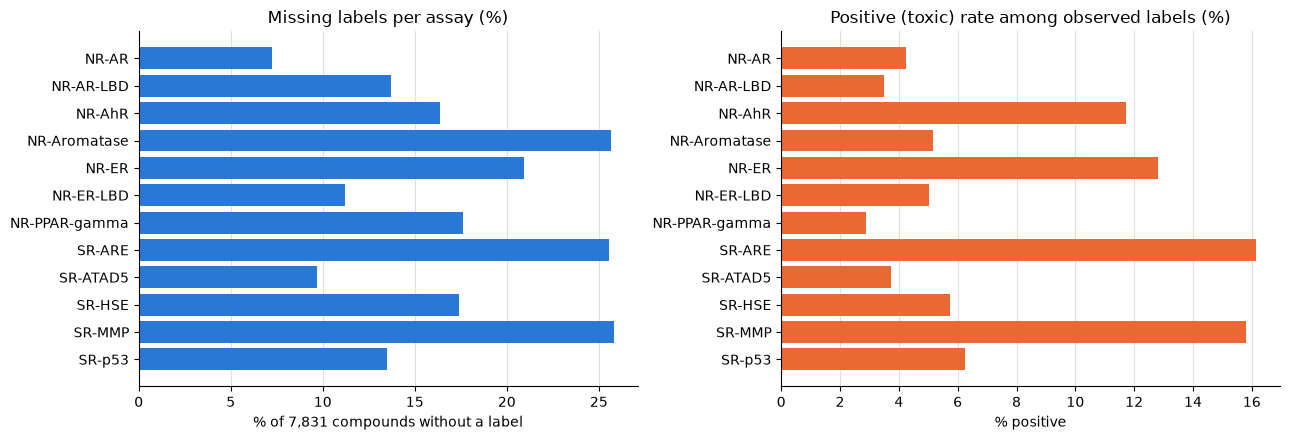

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].barh(stats_original["assay"], stats_original["missing_pct"], color="#2a78d6")
axes[0].set_title("Missing labels per assay (%)")
axes[0].set_xlabel("% of 7,831 compounds without a label")
axes[0].invert_yaxis()

axes[1].barh(stats_original["assay"], stats_original["positive_rate_pct"], color="#eb6834")
axes[1].set_title("Positive (toxic) rate among observed labels (%)")
axes[1].set_xlabel("% positive")
axes[1].invert_yaxis()

for ax in axes:
    ax.grid(axis="x", color="#e1e0d9")
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

## 4. Duplicate checks on the raw file

**What:** looks for exact duplicate rows, repeated IDs and repeated SMILES strings.
**Why:** duplicates can put the same molecule in both training and test data (leakage) or give it two different labels.

In [ ]:
print("Exact duplicate rows   :", df_raw.duplicated().sum())
print("Duplicate mol_id values:", df_raw["mol_id"].duplicated().sum())
print("Duplicate SMILES strings:", df_raw["smiles"].duplicated().sum())

Exact duplicate rows   : 0
Duplicate mol_id values: 0
Duplicate SMILES strings: 0


No duplicates are found at the *text* level. But two different SMILES strings can describe the **same molecule**,
for example `OCC` and `CCO` are both ethanol. To find those, we need canonical SMILES (next section).

## 5. SMILES validation and canonicalization (RDKit)

**What:** RDKit reads each SMILES. If it succeeds, we write the molecule back out as a **canonical SMILES**,
a single standard spelling for each molecule. If it fails, the SMILES is marked invalid and the error is saved.

Small demo first:

In [ ]:
for example in ["OCC", "CCO", "C(C)O"]:
    mol = Chem.MolFromSmiles(example)
    print(f"{example:6s} -> canonical: {Chem.MolToSmiles(mol)}")

OCC    -> canonical: CCO
CCO    -> canonical: CCO
C(C)O  -> canonical: CCO


All three spellings give the same canonical SMILES, `CCO`.

`dp.add_canonical_smiles()` repeats this for every row and adds four columns (the original columns are kept unchanged):

| New column | Meaning |
|---|---|
| `canonical_smiles` | RDKit canonical SMILES **with** stereochemistry (`None` if invalid) |
| `smiles_no_stereo` | canonical SMILES **without** stereochemistry, used to find stereoisomers |
| `smiles_valid` | `True` / `False` |
| `invalid_reason` | RDKit's error message for invalid SMILES |

In [ ]:
df_checked = dp.add_canonical_smiles(df_raw)

print("Valid SMILES  :", df_checked["smiles_valid"].sum())
print("Invalid SMILES:", (~df_checked["smiles_valid"]).sum())
df_checked[["mol_id", "smiles", "canonical_smiles", "smiles_valid"]].head()

Valid SMILES  : 7823
Invalid SMILES: 8


,mol_id,smiles,canonical_smiles,smiles_valid
0,TOX3021,CCOc1ccc2nc(S(N)(=O)=O)sc2c1,CCOc1ccc2nc(S(N)(=O)=O)sc2c1,True
1,TOX3020,CCN1C(=O)NC(c2ccccc2)C1=O,CCN1C(=O)NC(c2ccccc2)C1=O,True
2,TOX3024,CC[C@]1(O)CC[C@H]2[C@@H]3CCC4=CCCC[C@@H]4[C@H]...,CC[C@]1(O)CC[C@H]2[C@@H]3CCC4=CCCC[C@@H]4[C@H]...,True
3,TOX3027,CCCN(CC)C(CC)C(=O)Nc1c(C)cccc1C,CCCN(CC)C(CC)C(=O)Nc1c(C)cccc1C,True
4,TOX20800,CC(O)(P(=O)(O)O)P(=O)(O)O,CC(O)(P(=O)(O)O)P(=O)(O)O,True


In [ ]:
df_invalid = df_checked[~df_checked["smiles_valid"]]
df_invalid[["mol_id", "smiles", "invalid_reason"]]

,mol_id,smiles,invalid_reason
1322,TOX31563,NC(=O)NC1N=C(O[AlH3](O)O)NC1=O,RDKit sanitization failed: Explicit valence fo...
2290,TOX24724,O=CO[AlH3](OC=O)OC=O,RDKit sanitization failed: Explicit valence fo...
2297,TOX24723,CC(=O)O[AlH3](O)O,RDKit sanitization failed: Explicit valence fo...
3558,TOX24552,CC(=O)O[AlH3](O)OC(C)=O,RDKit sanitization failed: Explicit valence fo...
4565,TOX24622,CCOC(=O)/C=C(/C)O[AlH3](OC(C)CC)OC(C)CC,RDKit sanitization failed: Explicit valence fo...
4649,TOX7518,CCCCO[AlH3](OCCCC)OCCCC,RDKit sanitization failed: Explicit valence fo...
5538,TOX28892,O=S(=O)(OC[C@H]1O[C@H](O[C@]2(COS(=O)(=O)O[AlH...,RDKit sanitization failed: Explicit valence fo...
6723,TOX28623,CCCCCCCCCCCCCCCCCC(=O)O[AlH3](O)O,RDKit sanitization failed: Explicit valence fo...


**Interpretation:** every invalid SMILES contains aluminium written as `[AlH3]` bonded to extra oxygens.
That gives Al six bonds, which RDKit rejects as an impossible valence. We do **not** try to "repair" these structures by guessing.
They are excluded from splitting and saved in `exclusion_report.csv` with the reason.

In [ ]:
exclusion_report = df_invalid[["mol_id", "smiles", "invalid_reason"] + TARGET_COLUMNS].copy()
exclusion_report.insert(0, "original_row_index", df_invalid.index)
exclusion_report.insert(3, "exclusion_status", "excluded_invalid_smiles")
exclusion_report.to_csv("exclusion_report.csv", index=False)
print("Saved exclusion_report.csv with", len(exclusion_report), "rows")

Saved exclusion_report.csv with 8 rows


## 6. Duplicate structures and conflicting labels

**What:** now that every valid molecule has a canonical SMILES, we look for:
1. **Identical structures:** same canonical SMILES (same molecule, same stereochemistry).
2. **Stereoisomers:** same molecule when stereochemistry is ignored (for example the two mirror-image forms of a drug).

For each group we check whether the observed labels **conflict** (one record says 1, another says 0 for the same assay).

In [ ]:
duplicate_info = dp.duplicate_counts(df_checked)
for key, value in duplicate_info.items():
    print(f"{key:28s}: {value}")

exact_duplicate_rows        : 0
duplicate_mol_ids           : 0
duplicate_raw_smiles        : 0
duplicate_canonical_smiles  : 0
duplicate_ignoring_stereo   : 122


In [ ]:
same_structure_groups = dp.duplicate_groups(df_checked, "canonical_smiles")
stereo_groups = dp.duplicate_groups(df_checked, "smiles_no_stereo")

print("Groups of identical canonical structures:", len(same_structure_groups))
print("Groups of stereoisomers                 :", len(stereo_groups))
print("Records inside stereoisomer groups      :", stereo_groups["n_records"].sum())
print("Stereoisomer groups with conflicting labels:", stereo_groups["has_label_conflict"].sum())
stereo_groups.head()

Groups of identical canonical structures: 0
Groups of stereoisomers                 : 107
Records inside stereoisomer groups      : 229
Stereoisomer groups with conflicting labels: 31


,group_type,group_key,n_records,mol_ids,original_smiles,has_label_conflict,conflicting_assays
0,smiles_no_stereo,C#CC1(O)CCC2C3CCC4=CC(=O)CCC4C3CCC21CC,2,TOX16496;TOX27477,C#C[C@]1(O)CC[C@H]2[C@@H]3CCC4=CC(=O)CC[C@@H]4...,True,NR-Aromatase
1,smiles_no_stereo,C(=Cc1ccccc1)c1ccccc1,2,TOX6050;TOX6049,C(=C/c1ccccc1)\c1ccccc1;C(=C\c1ccccc1)\c1ccccc1,True,NR-AhR;NR-ER
2,smiles_no_stereo,C=C(C)C1CC=C(C)C(=O)C1,3,TOX27426;TOX21413;TOX256,C=C(C)C1CC=C(C)C(=O)C1;C=C(C)[C@@H]1CC=C(C)C(=...,False,
3,smiles_no_stereo,C=C(C)C1CC=C(C)CC1,3,TOX27078;TOX778;TOX9612,C=C(C)[C@@H]1CC=C(C)CC1;C=C(C)[C@H]1CC=C(C)CC1...,True,NR-AR
4,smiles_no_stereo,C=C1CCC2CC1C2(C)C,2,TOX7049;TOX21184,C=C1CCC2CC1C2(C)C;C=C1CC[C@H]2C[C@@H]1C2(C)C,False,


**Interpretation**
* There are **no identical canonical structures**, so no molecule appears twice and there is nothing to merge.
* Some molecules are **stereoisomers** of each other. They are *different* compounds, and stereoisomers can truly differ in biological activity,
  so different labels are not necessarily errors. We do **not** merge them and do **not** change their labels.

**Duplicate and conflict policy (applied in this project)**
1. The original CSV is never changed. All rows are kept in `split_manifest.csv`.
2. Duplicates are never silently deleted. All duplicate groups are written to `duplicate_audit.csv` (audit trail).
3. If identical canonical structures existed, they would be kept in the **same split** (guaranteed by the grouping in Section 8).
   Stereoisomers are kept in the same split as well, to avoid near-duplicate leakage.
4. Conflicting observed labels are **flagged for investigation** (`has_label_conflict`, `conflicting_assays`).
   We do not pick one label and we do not use majority voting. With only 2–3 records there is no real "majority", and the conflict may be real chemistry.

In [ ]:
duplicate_audit = pd.concat([same_structure_groups, stereo_groups], ignore_index=True)
duplicate_audit.to_csv("duplicate_audit.csv", index=False)
print("Saved duplicate_audit.csv with", len(duplicate_audit), "groups")

Saved duplicate_audit.csv with 107 groups


## 7. Label statistics after removing invalid SMILES

**What:** recomputes the label statistics for the valid molecules only, i.e. the molecules that will actually be split.

In [ ]:
df_valid = df_checked[df_checked["smiles_valid"]].copy()
print("Valid molecules:", len(df_valid))

overall_valid = dp.overall_label_counts(df_valid)
for key, value in overall_valid.items():
    print(f"{key:20s}: {value}")

stats_valid = dp.label_statistics(df_valid)
stats_valid

Valid molecules: 7823
rows                : 7823
total_label_cells   : 93876
observed_labels     : 77864
missing_labels      : 16012
missing_pct         : 17.06


,assay,positive,negative,observed,missing,missing_pct,positive_rate_pct,neg_to_pos_ratio
0,NR-AR,308,6950,7258,565,7.22,4.24,22.56
1,NR-AR-LBD,237,6514,6751,1072,13.70,3.51,27.49
2,NR-AhR,768,5774,6542,1281,16.37,11.74,7.52
3,NR-Aromatase,300,5515,5815,2008,25.67,5.16,18.38
4,NR-ER,791,5395,6186,1637,20.93,12.79,6.82
5,NR-ER-LBD,349,6599,6948,875,11.18,5.02,18.91
6,NR-PPAR-gamma,186,6257,6443,1380,17.64,2.89,33.64
7,SR-ARE,942,4883,5825,1998,25.54,16.17,5.18
8,SR-ATAD5,264,6801,7065,758,9.69,3.74,25.76
9,SR-HSE,372,6088,6460,1363,17.42,5.76,16.37


In [ ]:
comparison = pd.DataFrame({
    "assay": stats_original["assay"],
    "observed_original": stats_original["observed"],
    "observed_valid": stats_valid["observed"],
    "positive_original": stats_original["positive"],
    "positive_valid": stats_valid["positive"],
    "missing_original": stats_original["missing"],
    "missing_valid": stats_valid["missing"],
})
comparison["labels_lost"] = comparison["observed_original"] - comparison["observed_valid"]
comparison

,assay,observed_original,observed_valid,positive_original,positive_valid,missing_original,missing_valid,labels_lost
0,NR-AR,7265,7258,309,308,566,565,7
1,NR-AR-LBD,6758,6751,237,237,1073,1072,7
2,NR-AhR,6549,6542,768,768,1282,1281,7
3,NR-Aromatase,5821,5815,300,300,2010,2008,6
4,NR-ER,6193,6186,793,791,1638,1637,7
5,NR-ER-LBD,6955,6948,350,349,876,875,7
6,NR-PPAR-gamma,6450,6443,186,186,1381,1380,7
7,SR-ARE,5832,5825,942,942,1999,1998,7
8,SR-ATAD5,7072,7065,264,264,759,758,7
9,SR-HSE,6467,6460,372,372,1364,1363,7


In [ ]:
# The labels lost must be exactly the labels that belonged to the invalid rows
labels_in_invalid_rows = df_invalid[TARGET_COLUMNS].notnull().sum()
print("Labels lost == labels of invalid rows:",
      (comparison["labels_lost"].values == labels_in_invalid_rows.values).all())

Labels lost == labels of invalid rows: True


**Why the counts differ:** removing the invalid rows also removes the labels those rows had.
Each assay loses at most a few observed labels, and the missing counts drop slightly because there are fewer rows.
The positive rates hardly change, so excluding these 8 compounds does not change the class balance in any meaningful way.

## 8. Bemis–Murcko scaffolds

**What:** the *scaffold* of a molecule is its ring systems plus the linkers between them, with all side chains removed.
**Why:** a scaffold split puts molecules with the same core into the **same** split. The test set then contains chemotypes
the model has never seen, which is a harder and more honest evaluation than a random split.

We compute scaffolds **without stereochemistry**, so that stereoisomers always share a scaffold.

In [ ]:
example = "CC(=O)Oc1ccccc1C(=O)O"   # aspirin
print("Aspirin scaffold:", ss.get_scaffold(Chem.MolToSmiles(Chem.MolFromSmiles(example))))
print("Ethanol scaffold:", repr(ss.get_scaffold("CCO")), "(empty, because there is no ring)")

Aspirin scaffold: c1ccccc1
Ethanol scaffold: '' (empty, because there is no ring)


In [ ]:
df_grouped = ss.add_scaffold_groups(df_valid)

n_empty = (df_grouped["scaffold_smiles"] == "").sum()
print("Valid molecules              :", len(df_grouped))
print("Distinct non-empty scaffolds :", df_grouped.loc[df_grouped["has_ring_scaffold"], "scaffold_smiles"].nunique())
print("Molecules with EMPTY scaffold:", n_empty, f"({100 * n_empty / len(df_grouped):.1f}%)")
print("\nMost common scaffolds ('' = no ring):")
df_grouped["scaffold_smiles"].value_counts().head(8)

Valid molecules              : 7823
Distinct non-empty scaffolds : 2324
Molecules with EMPTY scaffold: 1775 (22.7%)

Most common scaffolds ('' = no ring):


scaffold_smiles
                       1775
c1ccccc1               1474
c1ccncc1                 89
c1ccc(Cc2ccccc2)cc1      83
c1ccc2ccccc2c1           69
C1CCCCC1                 63
c1c[nH+]c[nH]1           48
c1ccc(Oc2ccccc2)cc1      45
Name: count, dtype: int64

### 8.1 Policy for molecules with an empty scaffold

About one fifth of the molecules have **no ring**, so their Murcko scaffold is the empty string `""`.

* **Naive approach:** treat `""` as one scaffold. That one group (1,775 molecules) is far bigger than the whole validation or test set
  (~782 each), so it would have to go entirely into training. Validation and test would then contain **zero** acyclic molecules,
  and we could never measure how well a model does on them.
* **Policy used here:** the empty scaffold carries no chemical "core" information, so acyclic molecules are not treated as one series.
  Each distinct acyclic structure (ignoring stereochemistry) forms **its own small group**. These groups are shuffled with the
  fixed seed and allocated like any other small group.

**Consequence (stated honestly):** acyclic molecules in the test set do not have a "new scaffold" in the strict sense, because all of them share the empty scaffold
with acyclic training molecules. For these molecules the split behaves like a *structure-grouped random split*.
Identical structures and stereoisomers are still kept together. For all ring-containing molecules the split is a true scaffold split.
The `has_ring_scaffold` column in the manifest lets you evaluate the two groups separately later.

### 8.2 Allocation algorithm (seed = 42)
1. Groups bigger than half of the validation target (> ~391 molecules) are "big". In this data that is only the benzene scaffold.
2. Big groups and small groups are each shuffled with `random.Random(42)`.
3. Big groups first, then small groups. Each group goes to **train** if it still fits under 80%, otherwise to **validation** if it fits under 10%, otherwise to **test**.

The seed really matters: a different seed gives a different (but still leakage-free) split, and the same seed always gives the same split.

In [ ]:
RANDOM_SEED = 42
df_split = ss.scaffold_split(df_grouped, train_frac=0.8, val_frac=0.1, seed=RANDOM_SEED)

split_counts = ss.split_sizes(df_split)
split_counts

,split,count,pct
0,train,6258,79.99
1,validation,782,10.00
2,test,783,10.01


**Interpretation:** the proportions are close to 80/10/10 but not exact. Whole scaffold groups are moved together, so a split cannot stop at an exact
number of molecules. The greedy rule fills train and validation up to (never over) their targets, and the remainder goes to test.

In [ ]:
print("Molecules per split by scaffold type:")
pd.crosstab(df_split["has_ring_scaffold"].map({True: "has ring scaffold", False: "acyclic (empty)"}),
            df_split["split"], margins=True)

Molecules per split by scaffold type:


split,test,train,validation,All
has_ring_scaffold,,,,
acyclic (empty),207,1336,232,1775
has ring scaffold,576,4922,550,6048
All,783,6258,782,7823


## 9. Build the split manifest and validate the split

**What:** the manifest has **one row for every row of the original CSV**, including the 8 invalid ones (`split = "excluded"`).
Then we run the leakage checks.

In [ ]:
manifest_columns = ["original_row_index", "mol_id", "smiles", "canonical_smiles", "smiles_no_stereo",
                    "smiles_valid", "scaffold_smiles", "has_ring_scaffold", "scaffold_id", "split",
                    "exclusion_status", "invalid_reason"]

valid_part = df_split.copy()
valid_part["exclusion_status"] = "included"

invalid_part = df_checked[~df_checked["smiles_valid"]].copy()
invalid_part["scaffold_smiles"] = ""
invalid_part["has_ring_scaffold"] = False
invalid_part["scaffold_id"] = ""
invalid_part["split"] = "excluded"
invalid_part["exclusion_status"] = "excluded_invalid_smiles"

manifest = pd.concat([valid_part, invalid_part])
manifest["original_row_index"] = manifest.index
manifest = manifest.sort_values("original_row_index")[manifest_columns].reset_index(drop=True)

print("Manifest shape:", manifest.shape)
print(manifest["split"].value_counts())
manifest.head()

Manifest shape: (7831, 12)
split
train         6258
test           783
validation     782
excluded         8
Name: count, dtype: int64


,original_row_index,mol_id,smiles,canonical_smiles,smiles_no_stereo,smiles_valid,scaffold_smiles,has_ring_scaffold,scaffold_id,split,exclusion_status,invalid_reason
0,0,TOX3021,CCOc1ccc2nc(S(N)(=O)=O)sc2c1,CCOc1ccc2nc(S(N)(=O)=O)sc2c1,CCOc1ccc2nc(S(N)(=O)=O)sc2c1,True,c1ccc2scnc2c1,True,G00023,train,included,
1,1,TOX3020,CCN1C(=O)NC(c2ccccc2)C1=O,CCN1C(=O)NC(c2ccccc2)C1=O,CCN1C(=O)NC(c2ccccc2)C1=O,True,O=C1NC(=O)C(c2ccccc2)N1,True,G00441,train,included,
2,2,TOX3024,CC[C@]1(O)CC[C@H]2[C@@H]3CCC4=CCCC[C@@H]4[C@H]...,CC[C@]1(O)CC[C@H]2[C@@H]3CCC4=CCCC[C@@H]4[C@H]...,CCC1(O)CCC2C3CCC4=CCCCC4C3CCC21C,True,C1=C2CCC3C4CCCC4CCC3C2CCC1,True,G00100,validation,included,
3,3,TOX3027,CCCN(CC)C(CC)C(=O)Nc1c(C)cccc1C,CCCN(CC)C(CC)C(=O)Nc1c(C)cccc1C,CCCN(CC)C(CC)C(=O)Nc1c(C)cccc1C,True,c1ccccc1,True,G00001,train,included,
4,4,TOX20800,CC(O)(P(=O)(O)O)P(=O)(O)O,CC(O)(P(=O)(O)O)P(=O)(O)O,CC(O)(P(=O)(O)O)P(=O)(O)O,True,,False,G01008,validation,included,


In [ ]:
validation_results = ss.validate_split(manifest, n_input_rows=len(df_raw))
validation_results

,check,result,detail
0,manifest has one row per input row,PASS,7831 manifest rows vs 7831 input rows
1,every eligible compound has exactly one split,PASS,"7823 eligible, 7823 assigned"
2,invalid SMILES are excluded (not in any split),PASS,8 excluded rows
3,no scaffold group crosses splits,PASS,0 groups in >1 split
4,no non-empty Murcko scaffold crosses splits,PASS,0 scaffolds in >1 split
5,no canonical structure in more than one split,PASS,0 structures in >1 split
6,no stereoisomer set in more than one split,PASS,0 stereo-sets in >1 split
7,no compound ID in more than one split,PASS,0 IDs in >1 split
8,acyclic (empty-scaffold) molecules: documented...,PASS,"train=1336, validation=232, test=207 (by desig..."


In [ ]:
if (validation_results["result"] == "FAIL").any():
    raise AssertionError("At least one split check FAILED. Do not use these splits.")
print("All split checks passed.")

All split checks passed.


## 10. Class distribution in each split

**What:** positive / negative / missing counts for all 12 assays in train, validation and test.
**Why:** scaffold splits can make class balance differ between splits. It is important to know this before training a model.
Also, a split with very few positives for an assay gives a very noisy test score.

In [ ]:
split_class_stats = ss.class_distribution_by_split(df_split, TARGET_COLUMNS)

# Easier to read: one row per assay, one column per split
split_class_stats.pivot(index="assay", columns="split", values="positive_rate_pct")[["train", "validation", "test"]]

split,train,validation,test
assay,,,
NR-AR,3.62,4.92,8.69
NR-AR-LBD,2.98,3.56,7.74
NR-AhR,12.19,11.43,8.40
NR-Aromatase,5.39,3.45,4.98
NR-ER,12.30,14.17,15.26
NR-ER-LBD,4.71,5.16,7.45
NR-PPAR-gamma,2.92,3.44,2.06
SR-ARE,16.26,16.99,14.64
SR-ATAD5,3.66,5.20,2.88


In [ ]:
split_class_stats.pivot(index="assay", columns="split", values="positive")[["train", "validation", "test"]]

split,train,validation,test
assay,,,
NR-AR,211,36,61
NR-AR-LBD,161,24,52
NR-AhR,639,75,54
NR-Aromatase,252,20,28
NR-ER,608,89,94
NR-ER-LBD,262,36,51
NR-PPAR-gamma,150,23,13
SR-ARE,764,96,82
SR-ATAD5,207,37,20


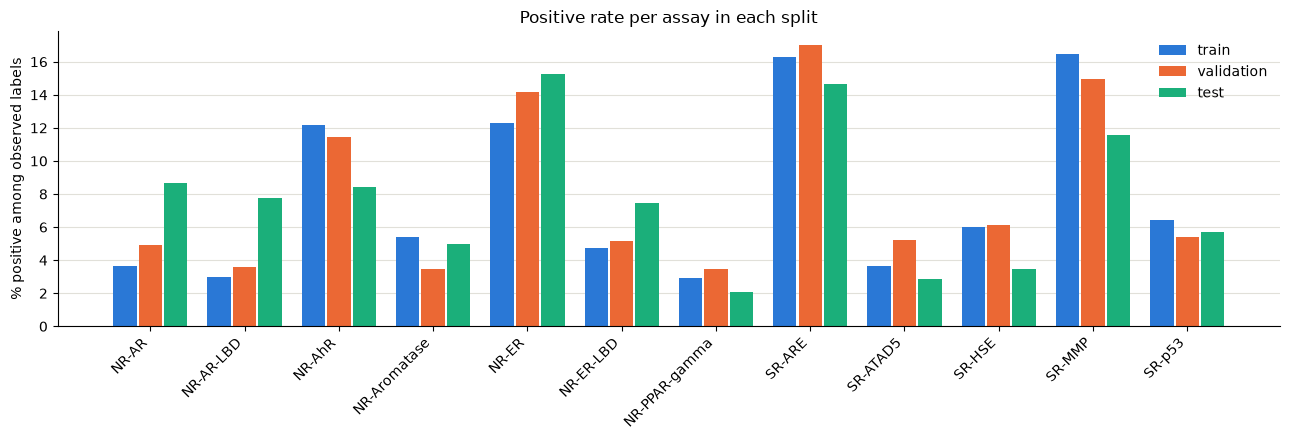

In [ ]:
pivot_rate = split_class_stats.pivot(index="assay", columns="split", values="positive_rate_pct").loc[TARGET_COLUMNS]
split_colors = {"train": "#2a78d6", "validation": "#eb6834", "test": "#1baf7a"}

x = np.arange(len(TARGET_COLUMNS))
width = 0.27
fig, ax = plt.subplots(figsize=(13, 4.5))
for i, name in enumerate(["train", "validation", "test"]):
    ax.bar(x + (i - 1) * width, pivot_rate[name], width * 0.92, label=name, color=split_colors[name])

ax.set_xticks(x)
ax.set_xticklabels(TARGET_COLUMNS, rotation=45, ha="right")
ax.set_ylabel("% positive among observed labels")
ax.set_title("Positive rate per assay in each split")
ax.legend(frameon=False)
ax.grid(axis="y", color="#e1e0d9")
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Interpretation:** the positive rates differ between splits, sometimes a lot. For NR-AR and NR-AR-LBD the test set has more than twice
the positive rate of the training set, while for SR-MMP and SR-HSE it is lower. This is expected with a scaffold split: some chemical series
are much more often active than others, and whole series move together.
We do **not** rebalance this, because forcing equal rates would break the scaffold separation.

Look at the count table above. Several assays have only about 13–40 positives in validation or test (e.g. NR-PPAR-gamma, SR-ATAD5, SR-HSE, NR-Aromatase).
Scores on so few positives are noisy, so later you should report several seeds or confidence intervals.

## 11. Export all output files

* `split_manifest.csv`: every original row with its canonical SMILES, scaffold, scaffold group ID and split (or exclusion).
* `train.csv`, `validation.csv`, `test.csv`: `mol_id`, original SMILES, canonical SMILES, 12 labels (missing labels stay empty).
* `dataset_summary.csv`: all statistics in one long table (`section, assay, metric, value`).

In [ ]:
manifest.to_csv("split_manifest.csv", index=False)

export_columns = ["mol_id", "smiles", "canonical_smiles"] + TARGET_COLUMNS
file_names = {"train": "train.csv", "validation": "validation.csv", "test": "test.csv"}
for name, file_name in file_names.items():
    part = df_split[df_split["split"] == name][export_columns]
    part.to_csv(file_name, index=False)
    print(f"Saved {file_name:15s} {part.shape}")

Saved train.csv       (6258, 15)
Saved validation.csv  (782, 15)
Saved test.csv        (783, 15)


In [ ]:
overall_info = {
    "source_file": DATA_FILE,
    "source_sha256": file_checksum,
    "rows": len(df_raw),
    "columns": df_raw.shape[1],
    "target_columns": len(TARGET_COLUMNS),
    "unique_mol_ids": df_raw["mol_id"].nunique(),
    "total_label_cells": overall_original["total_label_cells"],
    "observed_labels": overall_original["observed_labels"],
    "missing_labels": overall_original["missing_labels"],
    "missing_pct": overall_original["missing_pct"],
    "unexpected_target_values": int(total_unexpected),
    "valid_smiles": int(df_checked["smiles_valid"].sum()),
    "invalid_smiles": int((~df_checked["smiles_valid"]).sum()),
    "unique_canonical_structures": df_valid["canonical_smiles"].nunique(),
    "unique_structures_ignoring_stereo": df_valid["smiles_no_stereo"].nunique(),
    "stereoisomer_groups": len(stereo_groups),
    "stereoisomer_groups_with_label_conflict": int(stereo_groups["has_label_conflict"].sum()),
    "valid_observed_labels": overall_valid["observed_labels"],
    "valid_missing_labels": overall_valid["missing_labels"],
    "valid_missing_pct": overall_valid["missing_pct"],
    "unique_nonempty_scaffolds": df_grouped.loc[df_grouped["has_ring_scaffold"], "scaffold_smiles"].nunique(),
    "empty_scaffold_molecules": int(n_empty),
    "scaffold_groups_used_for_split": df_grouped["scaffold_id"].nunique(),
    "random_seed": RANDOM_SEED,
}
for key, value in duplicate_info.items():
    overall_info[key] = value

dataset_summary = dp.build_dataset_summary(overall_info, stats_original, stats_valid, split_counts, split_class_stats)
dataset_summary.to_csv("dataset_summary.csv", index=False)
print("Saved dataset_summary.csv", dataset_summary.shape)
dataset_summary.head(12)

Saved dataset_summary.csv (347, 4)


,section,assay,metric,value
0,overall,ALL,source_file,tox21 3.csv
1,overall,ALL,source_sha256,7d7e7facd853a63e79ddce4e9c3fcb7a0d83a1c300b603...
2,overall,ALL,rows,7831
3,overall,ALL,columns,14
4,overall,ALL,target_columns,12
5,overall,ALL,unique_mol_ids,7831
6,overall,ALL,total_label_cells,93972
7,overall,ALL,observed_labels,77946
8,overall,ALL,missing_labels,16026
9,overall,ALL,missing_pct,17.05


## 12. Final verification: reload the exported files

**What:** reads the files back from disk and checks them **independently** of the variables in memory.
**Why:** this proves the files on disk are correct, not just the DataFrames in the notebook.

In [ ]:
original = pd.read_csv(DATA_FILE)              # fresh copy of the input
train = pd.read_csv("train.csv")
validation = pd.read_csv("validation.csv")
test = pd.read_csv("test.csv")
manifest_loaded = pd.read_csv("split_manifest.csv")
excluded_loaded = pd.read_csv("exclusion_report.csv")

print("train      :", train.shape)
print("validation :", validation.shape)
print("test       :", test.shape)
print("manifest   :", manifest_loaded.shape)
print("excluded   :", excluded_loaded.shape)

n_split_total = len(train) + len(validation) + len(test)
print("\nActual proportions from the files (of", n_split_total, "valid molecules):")
for name, part in [("train", train), ("validation", validation), ("test", test)]:
    print(f"  {name:10s} {len(part):5d}  {100 * len(part) / n_split_total:.2f}%")

train      : (6258, 15)
validation : (782, 15)
test       : (783, 15)
manifest   : (7831, 12)
excluded   : (8, 17)

Actual proportions from the files (of 7823 valid molecules):
  train       6258  79.99%
  validation   782  10.00%
  test         783  10.01%


In [ ]:
checks = {}

# 1. Rows add up
checks["train + validation + test + excluded == original rows"] = (n_split_total + len(excluded_loaded) == len(original))

# 2. No ID or canonical structure in two split files
ids = pd.concat([train["mol_id"], validation["mol_id"], test["mol_id"]])
structures = pd.concat([train["canonical_smiles"], validation["canonical_smiles"], test["canonical_smiles"]])
checks["no mol_id in two split files"] = ids.is_unique
checks["no canonical SMILES in two split files"] = structures.is_unique
checks["excluded IDs are not in any split file"] = not excluded_loaded["mol_id"].isin(ids).any()

# 3. Split files agree with the manifest
for name, part in [("train", train), ("validation", validation), ("test", test)]:
    manifest_ids = set(manifest_loaded.loc[manifest_loaded["split"] == name, "mol_id"])
    checks[f"{name}.csv IDs == manifest '{name}' IDs"] = (set(part["mol_id"]) == manifest_ids)

# 4. Labels are exactly the original labels (missing stays missing)
all_splits = pd.concat([train, validation, test]).set_index("mol_id")
original_indexed = original.set_index("mol_id").loc[all_splits.index]
same_missing = (all_splits[TARGET_COLUMNS].isnull() == original_indexed[TARGET_COLUMNS].isnull()).all().all()
same_values = (all_splits[TARGET_COLUMNS].fillna(-1) == original_indexed[TARGET_COLUMNS].fillna(-1)).all().all()
checks["labels identical to original CSV (incl. missing)"] = same_missing and same_values
checks["original SMILES unchanged"] = (all_splits["smiles"] == original_indexed["smiles"]).all()

# 5. Only 0 / 1 / missing in the exported labels
exported_values = set(pd.unique(all_splits[TARGET_COLUMNS].values.ravel()))
exported_values = {v for v in exported_values if not pd.isnull(v)}
checks["exported labels are only 0, 1 or missing"] = exported_values.issubset({0.0, 1.0})

# 6. Input file was not modified
with open(DATA_FILE, "rb") as f:
    checks["input CSV unchanged (same SHA-256)"] = (hashlib.sha256(f.read()).hexdigest() == file_checksum)

final_checks = pd.DataFrame({"check": list(checks.keys()),
                             "result": ["PASS" if ok else "FAIL" for ok in checks.values()]})
final_checks

,check,result
0,train + validation + test + excluded == origin...,PASS
1,no mol_id in two split files,PASS
2,no canonical SMILES in two split files,PASS
3,excluded IDs are not in any split file,PASS
4,train.csv IDs == manifest 'train' IDs,PASS
5,validation.csv IDs == manifest 'validation' IDs,PASS
6,test.csv IDs == manifest 'test' IDs,PASS
7,labels identical to original CSV (incl. missing),PASS
8,original SMILES unchanged,PASS
9,"exported labels are only 0, 1 or missing",PASS


In [ ]:
assert (final_checks["result"] == "PASS").all(), "Some final checks failed!"
print("All final checks passed.")

All final checks passed.
